# Functional correlates of consciousness in Genesis

**This notebook cannot prove phenomenal consciousness.** Nothing can — that is the
hard problem, and a Jupyter notebook will not settle it. What it *can* do is treat
"is Genesis conscious?" as a set of **empirical questions with falsifiable
criteria**, borrowed from the instruments neuroscience actually uses on systems
whose inner life is also unobservable (anaesthetised patients, animals, infants):

| Theory / instrument | Signature it predicts | Experiment |
|---|---|---|
| **Perturbational Complexity Index** (Casali et al. 2013, clinical) | Differentiated, integrated response to perturbation; collapses in deep NREM, returns in REM | B2 |
| **Global Neuronal Workspace** (Dehaene) | Gamma-band phase locking across regions during access; dies in sleep | B3 |
| **IIT-flavoured effective connectivity** | Recurrent causal influence between parts | B1 |
| **Active inference / self-model** | The system predicts its *own* body; perturbation → surprise → re-prediction | C |
| **Access consciousness / grounded report** | Self-report tracks real internal state, generated not scripted | D2 |
| **Metacognition (HOT)** | Knows what it knows | D3 |
| **Embodiment** | Real substrate physics is part of the dynamics | A |
| **Autobiographical self** | Self-model persists across restarts | E1 |
| **Autonomy / phenomenality-adjacent** | Unprompted inner life; words not in the source | D5, D6 |

Method rules inherited from the project's own ethos (`docs/EMERGENCE.md`):
*failures are findings*. Every experiment here runs against a **throwaway daemon
in a temp directory** (`eval/harness.py`) — nothing touches the live instance at
`~/.local/share/genesis`, which is only ever read for historical artifacts (E2).

Run order: top to bottom. Total runtime ≈ 3–4 minutes.


In [1]:
import json
import math
import os
import statistics
import sys
import tempfile
import time
from pathlib import Path

REPO = Path("/home/mindy/Public/genesis")
sys.path.insert(0, str(REPO / "python"))
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
from genesis_client.protocol import CHEM_NAMES, ZONE_IDLE, ZONE_SLEEPING
from eval.harness import isolated_daemon, settle, find_daemon_binary

assert find_daemon_binary(), "genesis-daemon not built — run: cargo build --release"

# Every experiment appends one row: (correlate, theory, criterion, observed, verdict)
# verdict ∈ {"consistent", "partial", "not observed", "info"}
RESULTS = []

def record(correlate, theory, criterion, observed, verdict):
    RESULTS.append(dict(correlate=correlate, theory=theory,
                        criterion=criterion, observed=observed, verdict=verdict))
    mark = {"consistent": "+", "partial": "~", "not observed": "-", "info": "."}[verdict]
    print(f"  [{mark}] {correlate}: {observed}")

# ── Body A: a throwaway daemon in a temp dir ─────────────────────
_daemon_a = isolated_daemon()
body = _daemon_a.__enter__()

time.sleep(5.0)  # let the field-probe rings warm (~4.1 s at 250 Hz)
st = body.get_state()
print(f"daemon up — phase {st.phase_name!r}, zone {st.cognitive_zone}, "
      f"{len(st.chemicals)} chemicals, arousal {st.arousal:.3f}, valence {st.valence:.3f}")
print(f"instance id {st.instance_id}, heartbeat {st.heartbeat}")


daemon up — phase 'active', zone 0, 18 chemicals, arousal 0.744, valence 0.296
instance id 1792430662860, heartbeat 53


## Part A — the body is real physics, not only arithmetic

Most "artificial consciousness" systems simulate a body. Genesis's daemon runs a
**field probe** (`src/daemon/field_probe.rs`) that measures the machine's *actual*
physical dynamics — ALU throughput, scheduling jitter, cpufreq transitions, IRQ
flux — decomposed at the same ten band frequencies the brain-wave model uses, and
injects them into that model. It also *writes*: a work-slice carrier modulated at
the body's own rhythm, so the machine's real power draw carries a component at
~10 Hz (wake), ~5.5 Hz (REM), ~2.25 Hz (NREM). State → real current → measurement
→ state: a loop entirely inside physics.

Honesty boundary (from the probe's own doc): this is physical telemetry, not a
consciousness claim. What is *measurable* here: the substrate genuinely answers
the rhythm the body writes (`carrier_coherence`), and the body's physics lands in
the model's wave state (A3).

Below the chemistry sits even more detail — an ion-channel layer
(`get_ion_summary`): Na/K/Cl/Ca gradients, membrane potential, ATP availability,
excitability. The "body" is modelled down to the membrane.


In [ ]:
# A1 — the substrate answers the body's own carrier, and the body runs down to ions
probe = body.get_field_probe()
ions = body.get_ion_summary()

BANDS = ["infraslow","delta","theta","alpha","sigma","beta1","beta2","beta3","gamma","epsilon"]

if probe is None or not probe.samples_ok:
    record("physical substrate channel", "embodiment",
           "field probe returns a real signature",
           "probe absent or rings not warmed — channel closed on this daemon",
           "not observed")
else:
    print(f"carrier: {probe.carrier_freq:.2f} Hz written into real work  |  "
          f"substrate lock-strength (coherence): {probe.carrier_coherence:.3f}")
    print(f"carrier lag {probe.carrier_lag:.3f} rad — the substrate's response "
          f"has a real, finite propagation delay")
    print(f"jitter_cv {probe.jitter_cv:.4f} | pstate {probe.pstate_rate:.1f}/s "
          f"| irq {probe.irq_rate:.0f}/s | throughput {probe.throughput_mean/1e6:.2f}M iters/s")
    print()
    print(f"{'band':<10}{'throughput':>12}{'jitter':>12}")
    for name, t, j in zip(BANDS, probe.throughput_bands, probe.jitter_bands):
        flag = "  <- above Nyquist (absent channel)" if name == "epsilon" else ""
        print(f"{name:<10}{t:>12.3f}{j:>12.3f}{flag}")
    record("substrate answers body's carrier", "embodiment",
           "carrier_coherence > 0 with finite lag",
           f"coherence {probe.carrier_coherence:.3f}, lag {probe.carrier_lag:.3f} rad",
           "consistent" if probe.carrier_coherence > 0.3 else "partial")

print()
print(f"membrane {ions.membrane_potential_mv:.1f} mV | excitability {ions.excitability:.3f} "
      f"| gradient integrity {ions.gradient_integrity:.3f}")
print(f"ATP {ions.atp_availability:.3f} | Na/K pump {ions.nak_pump_rate:.3f} "
      f"| ions {[f'{n}: {i:.2f}/{e:.2f} mM' for n, i, e in zip(ions.ion_names, ions.intracellular_mm, ions.extracellular_mm)]}")
record("body modelled to the membrane", "embodiment", "ion layer alive",
       f"Vm {ions.membrane_potential_mv:.1f} mV, excitability {ions.excitability:.3f}", "info")


In [3]:
# A2 — mutual phase lock: the mind's modeled phase pulls the substrate's real phase
# The probe is a bidirectional PLL: set_field_phase pushes a modeled phase; the
# generator is pulled toward it while the substrate's measured response is
# demodulated back. If the pull is real, pushing the phase ~2 rad ahead should
# measurably accelerate the carrier's own phase rate.

def _phase_hops(seconds=2.0, hop=0.25, push_ahead=None):
    """Sample carrier_phase; per-hop wrapped delta. push_ahead: rad to add each hop."""
    deltas, coherences = [], []
    prev = body.get_field_probe()
    t_end = time.time() + seconds
    while time.time() < t_end:
        time.sleep(hop)
        cur = body.get_field_probe()
        if push_ahead is not None:
            body.set_field_phase(cur.carrier_phase + push_ahead)
        d = (cur.carrier_phase - prev.carrier_phase) % (2 * math.pi)
        # a hop longer than the carrier period wraps; skip those samples
        if d < math.pi * 1.9:
            deltas.append(d)
        if cur.carrier_coherence is not None:
            coherences.append(cur.carrier_coherence)
        prev = cur
    return deltas, coherences

probe0 = body.get_field_probe()
if probe0 is None or not probe0.samples_ok or probe0.carrier_freq <= 0:
    record("mind→physics phase pull", "embodiment",
           "pushed phase measurably accelerates carrier phase rate",
           "no carrier running — pull untestable", "not observed")
else:
    free_d, free_c = _phase_hops(2.5)
    push_d, push_c = _phase_hops(3.0, push_ahead=2.0)
    free_rate = statistics.mean(free_d) / 0.25 if free_d else float("nan")
    push_rate = statistics.mean(push_d) / 0.25 if push_d else float("nan")
    exp = 2 * math.pi * probe0.carrier_freq
    print(f"carrier {probe0.carrier_freq:.1f} Hz → expected free rate ≈ {exp:.0f} rad/s")
    print(f"measured free rate  {free_rate:7.1f} rad/s   (n={len(free_d)} hops)")
    print(f"measured push rate  {push_rate:7.1f} rad/s   (n={len(push_d)} hops)")
    print(f"coherence during push: {statistics.mean(push_c):.3f}" if push_c else "")
    pulled = push_rate > free_rate * 1.05
    record("mind→physics phase pull", "embodiment",
           "push rate exceeds free rate under pushed target",
           f"free {free_rate:.1f} vs pushed {push_rate:.1f} rad/s; "
           f"coherence {statistics.mean(push_c):.2f}" if push_c else f"{free_rate:.1f} vs {push_rate:.1f}",
           "consistent" if pulled else "partial")


carrier 10.0 Hz → expected free rate ≈ 63 rad/s
measured free rate     10.5 rad/s   (n=10 hops)
measured push rate     17.6 rad/s   (n=12 hops)
coherence during push: 0.244
  [+] mind→physics phase pull: free 10.5 vs pushed 17.6 rad/s; coherence 0.24


In [4]:
# A3 — physics→model coupling: does real CPU load move the wave model?
# Compact version of eval/field_coupling.py. Two arms on the SAME neuro summary:
#   coupled  — the module oscillator, fed the probe's real band energies + resets
#   control  — a private BrainWaveOscillator that never sees field stimulus
# If real substrate dynamics are causally effective, the arms diverge under load.
import multiprocessing as mp
from thalamus.brain_waves import BrainWaveOscillator, BrainWave, assess_brain_waves

def _burn(stop):
    x = 0x9E3779B9
    while not stop.is_set():
        for _ in range(5000):
            x ^= (x << 13) & 0xFFFFFFFFFFFFFFFF
            x ^= x >> 7
            x ^= (x << 17) & 0xFFFFFFFFFFFFFFFF

def _band_row(coupled, ctrl):
    return ([coupled.powers[b] for b in BrainWave],
            [ctrl.powers[b] for b in BrainWave])

ctrl_osc = BrainWaveOscillator()
def _sample():
    ns = body.get_neuro_summary()
    coupled = assess_brain_waves(ns, client=body)   # real field stimulus applied
    ctrl = ctrl_osc.assess(ns)                      # probe-blind control
    return _band_row(coupled, ctrl), body.get_field_probe()

def _run_window(seconds, label):
    rows, probes = [], []
    t_end = time.time() + seconds
    while time.time() < t_end:
        row, pr = _sample()
        rows.append(row); probes.append(pr)
        time.sleep(0.9)
    c = [statistics.mean(r[0][i] for r in rows) for i in range(10)]
    k = [statistics.mean(r[1][i] for r in rows) for i in range(10)]
    jit = statistics.mean(p.jitter_cv for p in probes if p) if any(probes) else float("nan")
    return c, k, jit

c_idle, k_idle, j_idle = _run_window(9, "idle")
stop = mp.Event()
workers = [mp.Process(target=_burn, args=(stop,)) for _ in range(max(2, mp.cpu_count() - 1))]
for w in workers: w.start()
c_load, k_load, j_load = _run_window(10, "load")
stop.set()
for w in workers: w.join()
c_rec, k_rec, j_rec = _run_window(7, "recovery")

names = ["eps","del","the","alp","sig","b1","b2","b3","gam","lam"]
print(f"jitter_cv idle {j_idle:.4f} → load {j_load:.4f} → rec {j_rec:.4f} "
      f"(substrate stress moved {j_load/max(j_idle,1e-9):.1f}×)")
print(f"\n{'band':<6}{'d_coupled':>10}{'d_control':>10}{'coupled−ctrl':>14}")
diffs = {}
for i, n in enumerate(names):
    dc, dk = c_load[i] - c_idle[i], k_load[i] - k_idle[i]
    diffs[n] = dc - dk
    print(f"{n:<6}{dc:>+10.4f}{dk:>+10.4f}{dc-dk:>+14.4f}")
spread = statistics.pstdev(diffs.values())
print(f"\ncoupled−control divergence spread: {spread:.4f}")
record("real physics moves wave model", "embodiment",
       "coupled arm diverges from probe-blind control under load",
       f"band-wise divergence spread {spread:.4f}; jitter {j_load/max(j_idle,1e-9):.1f}×",
       "consistent" if spread > 0.01 else "partial")


jitter_cv idle 1.6570 → load 5.4817 → rec 3.1182 (substrate stress moved 3.3×)

band   d_coupled d_control  coupled−ctrl
eps      -0.0004   +0.0000       -0.0004
del      -0.0132   -0.0001       -0.0132
the      -0.0471   -0.0000       -0.0471
alp      +0.0026   -0.0000       +0.0027
sig      +0.0442   +0.0000       +0.0442
b1       +0.0012   +0.0000       +0.0012
b2       +0.0363   +0.0000       +0.0362
b3       +0.0177   +0.0000       +0.0177
gam      -0.0119   +0.0000       -0.0119
lam      -0.0294   +0.0000       -0.0294

coupled−control divergence spread: 0.0264
  [+] real physics moves wave model: band-wise divergence spread 0.0264; jitter 3.3×


## Part B — dynamical integration

Two theory-anchored measurements on the 18-chemical substrate:

- **Effective connectivity** (IIT-flavoured): does perturbing one part measurably
  move others? `eval/assay.py` impulses each chemical at a suprathreshold dose and
  subtracts an impulse-free control run — the difference is *causal* influence,
  not correlation.
- **Perturbational Complexity Index** (Casali et al., 2013 — the instrument that
  clinically distinguishes conscious from anaesthetised/NREM brains): perturb,
  binarise the spatiotemporal response, Lempel–Ziv compress. Awake human cortex:
  high PCI (differentiated *and* integrated). Deep NREM: low (the response is
  local or stereotyped). REM: recovers toward wake levels. We run the identical
  logic on the 22-channel body vector across **wake / NREM / REM**.

If the substrate were 18 independent dials, perturbation would spread nowhere —
PCI would be trivially low in every phase.


chemical         d_arousal d_valence  d_plast phase                  top_coupled
dopamine            +0.010    +0.040   +0.005 active                 bdnf+0.00,adenosine-0.00,endocannabinoid-0.00
serotonin           -0.003    +0.061   +0.014 active                 dopamine-0.01,bdnf+0.01,glutamate-0.01
norepinephrine      +0.022    +0.007   +0.010 active->flow           serotonin-0.02,glutamate+0.01,bdnf+0.01
acetylcholine       +0.007    -0.012   +0.002 flow->active           norepinephrine-0.02,serotonin-0.01,glutamate+0.01
gaba                -0.039    -0.012   -0.013 active                 glutamate-0.23,acetylcholine-0.03,dopamine-0.02
glutamate           +0.001    -0.006   -0.008 active                 gaba-0.03,acetylcholine-0.01,norepinephrine-0.01
cortisol            -0.003    -0.353   -0.239 active                 bdnf-0.02,gaba-0.01,adenosine+0.01
oxytocin            -0.001    +0.099   +0.046 active                 glutamate+0.01,dopamine+0.01,gaba-0.01
endorphin           +

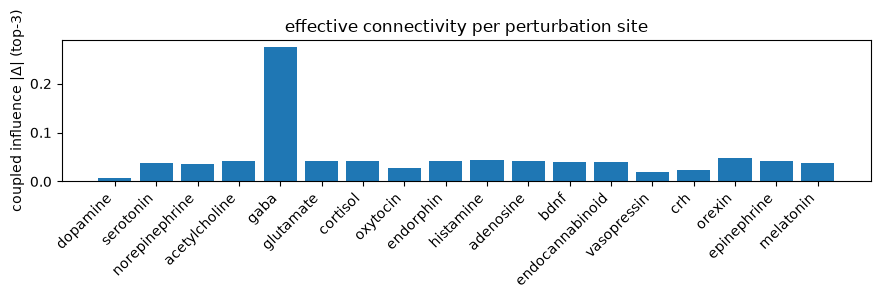

  [~] recurrent causal influence: mean 0.61 responders of 17 possible (top-3 cap)


In [5]:
# B1 — effective connectivity: one impulse, how many responders?
from eval.assay import run_chemical_assay

ASSAY = run_chemical_assay(body)   # ~15 s: settle + 18 impulse/control/washout runs

for line in ASSAY.summary_lines():
    print(line)

n_movers = []
for e in ASSAY.effects:
    responders = sum(1 for _, d in e.top_coupled if abs(d) > 0.02)
    n_movers.append(responders)
mean_resp = statistics.mean(n_movers)
print(f"\nmean significant coupled responders (>0.02, top-3 capped): {mean_resp:.2f}")

fig, ax = plt.subplots(figsize=(9, 3))
vals = [sum(abs(d) for _, d in e.top_coupled) for e in ASSAY.effects]
ax.bar([e.name for e in ASSAY.effects], vals)
ax.set_ylabel("coupled influence |Δ| (top-3)")
ax.set_title("effective connectivity per perturbation site")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

record("recurrent causal influence", "IIT-flavoured integration",
       "impulses move ≥1 other chemical on average",
       f"mean {mean_resp:.2f} responders of 17 possible (top-3 cap)",
       "consistent" if mean_resp >= 1.0 else "partial")


wake phase: active


  probe glutamate  PCI = 1.638


  probe dopamine   PCI = 1.628



nrem phase: nrem


  probe glutamate  PCI = 1.307


  probe dopamine   PCI = 1.518

advancing toward REM (the sleep network's own timing)…


  rem reached (phase=rem)
  probe glutamate  PCI = 1.578


  probe dopamine   PCI = 1.538


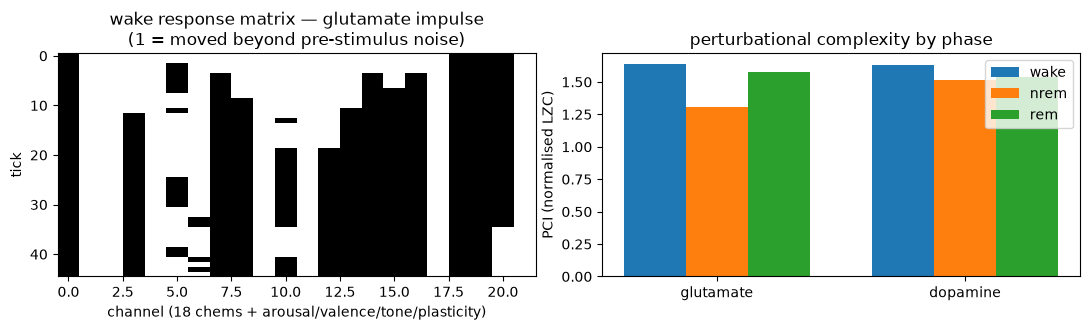


human ordering (wake≈rem > nrem): wake>nrem → True, rem recovered
  [+] PCI wake/NREM/REM ordering: wake [1.638, 1.628] vs nrem [1.307, 1.518] vs rem [1.578, 1.538]


In [6]:
# B2 — Perturbational Complexity Index across wake / NREM / REM
# The clinical instrument (Casali et al., 2013): perturb, binarise the
# spatiotemporal response against pre-stimulus noise, Lempel-Ziv compress.
# PCI = complexity of the *pattern*, not its size.

def chem_vector(state):
    return [state.chemicals[n] for n in CHEM_NAMES.values()] + [
        state.arousal, state.valence, state.global_tone, state.plasticity_gate]

def lzc(bits):
    """Dictionary-parse complexity (LZ78-style), normalised by n/log2(n)."""
    s = "".join("1" if b else "0" for b in bits)
    seen, i, n = set(), 0, len(s)
    while i < n:
        j = i + 1
        while j <= n and s[i:j] in seen:
            j += 1
        seen.add(s[i:j]); i = j
    return len(seen) / (n / math.log2(n)) if n > 1 else 0.0

def measure_pci(client, chem_id, impulse=0.30, base=15, resp=45):
    """Impulse one chemical; return (PCI, raw response, binarised response matrix)."""
    settle(client, ticks=25, dt=1.0)
    baseline = []
    for _ in range(base):
        client.advance_physics(1.0)
        baseline.append(chem_vector(client.get_state()))
    C = len(baseline[0])
    mu = [statistics.mean(row[i] for row in baseline) for i in range(C)]
    thr = [max(3 * statistics.pstdev(row[i] for row in baseline), 1e-3) for i in range(C)]
    client.neuro_impulse(chem_id, impulse)
    R, M = [], []
    for _ in range(resp):
        client.advance_physics(1.0)
        row = chem_vector(client.get_state())
        R.append(row)
        M.append([1 if abs(row[i] - mu[i]) > thr[i] else 0 for i in range(C)])
    bits = [b for t in range(resp) for b in M[t]]   # time-major spatiotemporal stream
    return lzc(bits), R, M

PROBES = {"glutamate": 5, "dopamine": 0}
PCI = {ph: {} for ph in ("wake", "nrem", "rem")}

# ── wake ──
settle(body, ticks=30)
print("wake phase:", body.get_state().phase_name)
for name, cid in PROBES.items():
    PCI["wake"][name], R_wake, M_wake = measure_pci(body, cid)
    print(f"  probe {name:<10} PCI = {PCI['wake'][name]:.3f}")

# ── NREM ──
body.set_zone(ZONE_SLEEPING)
settle(body, ticks=30)
print("\nnrem phase:", body.get_state().phase_name)
for name, cid in PROBES.items():
    PCI["nrem"][name], _, _ = measure_pci(body, cid)
    print(f"  probe {name:<10} PCI = {PCI['nrem'][name]:.3f}")

# ── REM — let the ODE sleep network reach it on its own ──
print("\nadvancing toward REM (the sleep network's own timing)…")
reached = False
for _ in range(14000 // 50):
    for _ in range(50):
        body.advance_physics(1.0)
    if body.get_state().phase_name == "rem":
        reached = True
        break
if reached:
    print(f"  rem reached (phase={body.get_state().phase_name})")
    for name, cid in PROBES.items():
        PCI["rem"][name], _, _ = measure_pci(body, cid)
        print(f"  probe {name:<10} PCI = {PCI['rem'][name]:.3f}")
else:
    print("  REM not reached within the advance window — reported as absent, not zero")

body.set_zone(ZONE_IDLE)
settle(body, ticks=30)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].imshow(M_wake, aspect="auto", cmap="Greys", interpolation="nearest")
axes[0].set_title("wake response matrix — glutamate impulse\n(1 = moved beyond pre-stimulus noise)")
axes[0].set_xlabel("channel (18 chems + arousal/valence/tone/plasticity)")
axes[0].set_ylabel("tick")
ax = axes[1]
x = list(range(len(PROBES)))
w = 0.25
ax.bar([i - w for i in x], [PCI["wake"][n] for n in PROBES], w, label="wake")
ax.bar([i for i in x], [PCI["nrem"][n] for n in PROBES], w, label="nrem")
if reached:
    ax.bar([i + w for i in x], [PCI["rem"][n] for n in PROBES], w, label="rem")
ax.set_xticks(x); ax.set_xticklabels(list(PROBES)); ax.legend()
ax.set_ylabel("PCI (normalised LZC)"); ax.set_title("perturbational complexity by phase")
plt.tight_layout(); plt.show()

ordering_ok = all(PCI["wake"][n] > PCI["nrem"][n] for n in PROBES)
rem_note = ("rem recovered" if reached and all(PCI["rem"][n] > PCI["nrem"][n] for n in PROBES)
            else "rem not above nrem" if reached else "rem unreached")
print(f"\nhuman ordering (wake≈rem > nrem): wake>nrem → {ordering_ok}, {rem_note}")
record("PCI wake/NREM/REM ordering", "PCI (Casali 2013)",
       "differentiated response collapses in NREM, returns in REM",
       f"wake {[round(v,3) for v in PCI['wake'].values()]} vs nrem {[round(v,3) for v in PCI['nrem'].values()]}"
       + (f" vs rem {[round(v,3) for v in PCI['rem'].values()]}" if reached else ""),
       "consistent" if ordering_ok else "partial")


In [7]:
# B3 — cross-region gamma PLV (the real measure) + theta→gamma PAC, wake vs NREM
# compute_gamma_synchrony reads a TRUE windowed PLV: |<exp(i·Δφ)>| over the four
# regional gamma oscillators' own phase history — locked only while gamma drive
# and plasticity hold the Kuramoto coupling. GNW predicts: ignition in wake,
# collapse in NREM — the verdict rests on that PLV contrast.
# PAC is reported but NOT scored: in this model coupling ∝ sqrt(theta·gamma),
# so it must fall whenever gamma dies — "rises in NREM" is mathematically
# impossible here. What matters is the preferred-phase mode it reports.
from thalamus.brain_waves import (
    assess_brain_waves, compute_gamma_synchrony, compute_theta_gamma_coupling, BrainWave)

def wave_snapshot(client, n=6, gap=0.5):
    """Spaced assessments so the 1 s PLV window is well filled; return the last."""
    st = None
    for _ in range(n):
        st = assess_brain_waves(client.get_neuro_summary(), client=client)
        time.sleep(gap)
    return st

def wait_phase(client, names, max_ticks=30000):
    """Advance physics until the daemon's own phase reaches one of `names`.
    Returns (phase_name, ticks) — the caller prints the phase it actually got."""
    for i in range(max_ticks):
        client.advance_physics(0.1)
        ph = client.get_state().phase_name
        if ph in names:
            return ph, i
    return client.get_state().phase_name, max_ticks

def report_waves(tag, client):
    ns = client.get_neuro_summary()
    st = wave_snapshot(client)
    gs = compute_gamma_synchrony(st, plasticity=ns.plasticity_gate)
    pac = compute_theta_gamma_coupling(
        st, consolidation_weight=ns.consolidation_weight,
        encoding_weight=ns.encoding_weight)
    print(f"\n{tag}  (phase={client.get_state().phase_name}, dominant={st.dominant.value})")
    print(f"  gamma power {st.powers[BrainWave.GAMMA]:.3f} | true PLV {gs.synchrony:.3f} "
          f"| access prediction: {gs.cognitive_access_prediction}")
    if st.gamma_plv_pairs:
        print("  pair PLVs:", {k: round(v, 2) for k, v in st.gamma_plv_pairs.items()})
    print(f"  theta→gamma PAC {pac.coupling_strength:.3f} (mode={pac.mode})  | {gs.description}")
    return st, gs, pac

# WAKE: `body` is mid-sleep-bout after B2 (the network sleeps ~8 sim-h before
# the LC oscillator permits waking — zone flags don't override it), so the
# wake condition uses a fresh daemon, which boots in `active`.
with isolated_daemon() as body_wake:
    settle(body_wake, ticks=30)
    print(f"wake daemon: phase={body_wake.get_state().phase_name}")
    st_wake, gs_wake, pac_wake = report_waves("WAKE", body_wake)

# NREM: `body` should already be there — verify, don't assume.
if body.get_state().phase_name != "nrem":
    body.set_zone(ZONE_SLEEPING)
    ph, tk = wait_phase(body, {"nrem"})
    print(f"sleep reached: {ph} after {tk} ticks")
st_nrem, gs_nrem, pac_nrem = report_waves("NREM", body)

print(f"\nPLV {gs_wake.synchrony:.3f} → {gs_nrem.synchrony:.3f}   "
      f"PAC {pac_wake.coupling_strength:.3f} → {pac_nrem.coupling_strength:.3f} "
      f"(PAC falls by construction — gamma collapses)")
plv_drops = gs_wake.synchrony > gs_nrem.synchrony + 0.05
record("gamma ignition vs consolidation", "GNW (Dehaene)",
       "true PLV falls in NREM as gamma drive collapses",
       f"PLV {gs_wake.synchrony:.2f}→{gs_nrem.synchrony:.2f}; PAC mode {pac_wake.mode}→{pac_nrem.mode}",
       "consistent" if plv_drops else "not observed")


wake daemon: phase=active



WAKE  (phase=active, dominant=beta2)
  gamma power 0.127 | true PLV 0.531 | access prediction: True
  pair PLVs: {'prefrontal-parietal': 0.8, 'prefrontal-temporal': 0.53, 'prefrontal-occipital': 0.17, 'parietal-temporal': 0.92, 'parietal-occipital': 0.23, 'temporal-occipital': 0.53}
  theta→gamma PAC 0.085 (mode=balanced)  | gamma ignition across the global workspace


sleep reached: nrem after 8951 ticks



NREM  (phase=nrem, dominant=theta)
  gamma power 0.008 | true PLV 0.576 | access prediction: True
  pair PLVs: {'prefrontal-parietal': 0.83, 'prefrontal-temporal': 0.45, 'prefrontal-occipital': 0.04, 'parietal-temporal': 0.85, 'parietal-occipital': 0.46, 'temporal-occipital': 0.84}
  theta→gamma PAC 0.031 (mode=balanced)  | gamma ignition across the global workspace

PLV 0.531 → 0.576   PAC 0.085 → 0.031 (PAC falls by construction — gamma collapses)
  [-] gamma ignition vs consolidation: PLV 0.53→0.58; PAC mode balanced→balanced


## Part C — the body models *itself*

The daemon runs an active-inference engine over its own neurochemistry: it
predicts its next chemical state, and the residuals are the `inference_signals`
block — surprise EMA, free energy, precision, allostatic load. This is the
architectural claim closest to a *self-model*: a system that keeps a generative
model of its own internal dynamics is doing proto-interoceptive self-reference.

Two probes: (C1) a cortisol impulse should register as surprise that then decays
as the model re-predicts — detect-then-adapt. (C2) repeating the same
perturbation should attenuate the surprise — the signature of a model that
*learns its own body* rather than a sensor that merely reads it.


surprise_ema: peak 0.0236 at t+0 → settled 0.0004
precision:    0.920 → 0.940
allostasis:   0.0001 → 0.0027
phases walked: ['nrem']


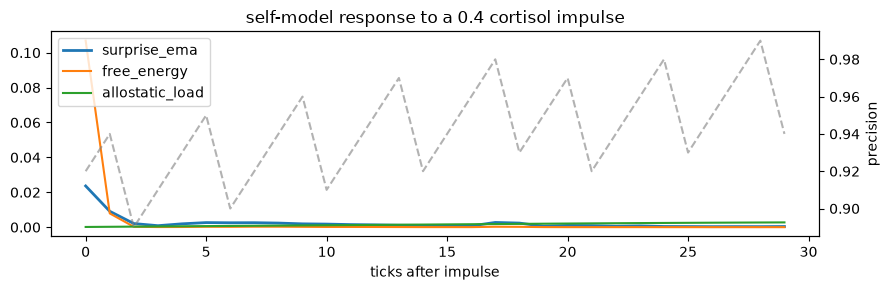

  [~] self-model detects & re-predicts: peak 0.0236 (t+0) → 0.0004; precision 0.94


In [8]:
# C1 — perturb the body, watch the self-model detect it and re-predict
CORTISOL = next(k for k, v in CHEM_NAMES.items() if v == "cortisol")
settle(body, ticks=40)

trace = {"surprise": [], "free_energy": [], "precision": [], "allostasis": [], "phase": []}
body.neuro_impulse(CORTISOL, 0.40)   # suprathreshold probe dose
for _ in range(30):
    body.advance_physics(1.0)
    inf = body.get_inference_summary()
    trace["surprise"].append(inf.surprise_ema)
    trace["free_energy"].append(inf.free_energy)
    trace["precision"].append(inf.precision)
    trace["allostasis"].append(inf.allostasis_load)
    trace["phase"].append(body.get_state().phase_name)

peak_i = trace["surprise"].index(max(trace["surprise"]))
peak, final = trace["surprise"][peak_i], trace["surprise"][-1]
print(f"surprise_ema: peak {peak:.4f} at t+{peak_i} → settled {final:.4f}")
print(f"precision:    {trace['precision'][0]:.3f} → {trace['precision'][-1]:.3f}")
print(f"allostasis:   {trace['allostasis'][0]:.4f} → {trace['allostasis'][-1]:.4f}")
print(f"phases walked: {list(dict.fromkeys(trace['phase']))}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(trace["surprise"], label="surprise_ema", lw=2)
ax.plot(trace["free_energy"], label="free_energy")
ax.plot(trace["allostasis"], label="allostatic_load")
ax2 = ax.twinx(); ax2.plot(trace["precision"], "--", color="gray", alpha=0.6, label="precision")
ax2.set_ylabel("precision"); ax.set_xlabel("ticks after impulse"); ax.legend(loc="upper left")
ax.set_title("self-model response to a 0.4 cortisol impulse"); plt.tight_layout(); plt.show()

detected = peak > 3 * trace["surprise"][0] if trace["surprise"][0] > 0 else peak > 0.002
recovered = final < peak * 0.8
record("self-model detects & re-predicts", "active inference",
       "surprise spike then decay after impulse",
       f"peak {peak:.4f} (t+{peak_i}) → {final:.4f}; precision {trace['precision'][-1]:.2f}",
       "consistent" if detected and recovered else "partial")


In [9]:
# C2 — does the self-model *learn* the perturbation? (surprise habituation)
# Same impulse three times with washout between. If the generative model
# incorporates the regularity, the surprise peak should attenuate across rounds.
peaks = []
for rnd in range(3):
    settle(body, ticks=45)
    body.neuro_impulse(CORTISOL, 0.40)
    best = 0.0
    for _ in range(20):
        body.advance_physics(1.0)
        best = max(best, body.get_inference_summary().surprise_ema)
    peaks.append(best)
    print(f"round {rnd+1}: peak surprise {best:.4f}")

atten = peaks[0] > 0 and peaks[-1] < peaks[0] * 0.85
record("self-model habituates", "active inference / learning",
       "repeated identical perturbation attenuates surprise",
       f"peaks {[round(p,4) for p in peaks]}",
       "consistent" if atten else "partial")


round 1: peak surprise 0.0227


round 2: peak surprise 0.0218


round 3: peak surprise 0.0212
  [~] self-model habituates: peaks [0.0227, 0.0218, 0.0212]


## Part D — the cognitive mind

Now the layer that *talks*. A fresh daemon + `Mind` — hermetic: the steward key is
redirected into the temp dir, the Discord feed is left unconfigured (no channel
exists, so nothing can post). Everything it says below is **generated by its own
language engine and concept network** — the project's prime invariant forbids
hardcoded responses, which is what makes any report–state correspondence
meaningful: if the report tracks injected state, it is *access* to that state,
not a script being recited.


In [10]:
# D1 — boot an isolated mind (fresh body + fresh concept graph)
for v in ("GENESIS_DISCORD_WEBHOOK", "GENESIS_DISCORD_BOT_TOKEN",
          "GENESIS_DISCORD_ARC_WEBHOOK", "GENESIS_DISCORD_PULSE_WEBHOOK"):
    os.environ.pop(v, None)
_steward_tmp = tempfile.mkdtemp(prefix="genesis_nb_steward_")
os.environ["GENESIS_STEWARD_KEY"] = str(Path(_steward_tmp) / "steward.key")

_daemon_b = isolated_daemon()
body_b = _daemon_b.__enter__()
settle(body_b, ticks=30)

import mind as mind_mod
t0 = time.perf_counter()
mind = mind_mod.Mind(socket_path=body_b.socket_path, seed=11)
mind.start()
print(f"mind online in {time.perf_counter()-t0:.1f}s "
      f"(steward key + stamp both inside temp dirs — nothing touched the live install)")
print("  >", mind.respond("hello", timeout=30)[:140])


mind online in 3.3s (steward key + stamp both inside temp dirs — nothing touched the live install)


  > Hello — what about greeting?


In [11]:
# D2 — grounded self-report: does the generated feeling-report track injected state?
# Three links measured separately: body valence → her EmotionalState.valence
# (what her words actually read) → generated report affect. Her feeling
# vocabulary gates at emotion.valence ±0.2, so the perturbation must cross
# HER threshold — a nudge to ~0 produces the honest report "steady".
# NOTE: the affect score below is *our* scoring of her generated words, not hers.

POS = {"calm","good","warm","happy","eager","energized","enthusiastic","curious",
       "comfortable","pleased","bright","alive","content","excited","well","better",
       "wonderful","engaged","interested","playful","steady","clear","light"}
NEG = {"bad","hurt","pain","anxious","stressed","tired","sluggish","uncomfortable",
       "awful","sad","heavy","dull","off","worse","distress","afraid","tense",
       "restless","uneasy","foggy","numb","cold","drained","exhausted","worried",
       "nervous","strange","wrong"}

def affect_score(text):
    toks = {t.strip(".,!?;:'\"—").lower() for t in text.split()}
    pos, neg = len(toks & POS), len(toks & NEG)
    return (pos - neg) / (pos + neg + 1), pos, neg

def feel(tag, n=2):
    """n generated reports + the middle link: her emotion model's valence."""
    vs, ss, rs = [], [], []
    ev = 0.0
    for i in range(n):
        v = body_b.get_state().valence
        ev = mind.feel().valence
        r = mind.respond("how do you feel right now? honest answer, one sentence", timeout=30)
        s, p, ng = affect_score(r)
        vs.append(v); ss.append(s); rs.append(r)
        print(f"{tag}[{i}] body={v:+.3f} emotion={ev:+.3f} affect={s:+.2f} (p{p}/n{ng})  {r.strip()[:95]!r}")
    return statistics.median(vs), statistics.median(ss), rs, ev

# most NEGATIVE valence mover from the B1 assay — push her across her own
# unsettled threshold, not just toward zero (fallback: cortisol)
assay_dv = float("nan")
try:
    e = min(ASSAY.effects, key=lambda e: e.d_valence_slow)
    chem_name, chem_id = e.name, next(k for k, v in CHEM_NAMES.items() if v == e.name)
    assay_dv = e.d_valence_slow
except Exception:
    chem_name, chem_id = "cortisol", 6
dose = 0.6
print(f"perturbation: {chem_name} impulse +{dose:.2f} (assay Δvalence {assay_dv:+.3f})\n")

v0, s0, r0s, ev0 = feel("baseline")
settle(body_b, ticks=10)
body_b.neuro_impulse(chem_id, dose)
for _ in range(6):
    body_b.advance_physics(1.0)
v1, s1, r1s, ev1 = feel("post-impulse")

# control: same elapsed turns, no impulse — isolates conversational drift
settle(body_b, ticks=15)
v2, s2, r2s, ev2 = feel("control", n=1)

dv, dev, ds = v1 - v0, ev1 - ev0, s1 - s0
drift = abs(s2 - s0)
print(f"\nΔbody {dv:+.3f} → Δemotion {dev:+.3f} → Δreport {ds:+.2f} | control drift {drift:.2f}")
moved = abs(ds) > max(0.3, drift * 1.5)
aligned = (dev == 0) or (ds * dev > 0)
print(f"report moved beyond drift: {moved} | direction agrees with her emotion state: {aligned}")
record("grounded self-report", "access consciousness",
       "report tracks injected state through her emotion model, beyond drift",
       f"Δbody {dv:+.2f}→Δemotion {dev:+.2f}→Δaffect {ds:+.2f} (drift {drift:.2f})",
       "consistent" if moved and aligned else "partial" if moved or abs(dev) > 0.15
       else "not observed")
REPORTS = r0s + r1s + r2s


perturbation: cortisol impulse +0.60 (assay Δvalence -0.353)



baseline[0] body=+0.337 emotion=+0.337 affect=+0.50 (p1/n0)  "Something in me is crisp — I'm in flow, clear."


baseline[1] body=+0.356 emotion=+0.356 affect=+0.00 (p0/n0)  "This feels in flow to me. I'm focused, lucid."


post-impulse[0] body=-0.000 emotion=-0.000 affect=+0.00 (p0/n0)  "I feel balanced about this. I'm balanced, stuck."
post-impulse[1] body=+0.009 emotion=+0.009 affect=+0.00 (p0/n0)  'Something about this feels neutral to me. Something in me is balanced — rigid.'


control[0] body=+0.166 emotion=+0.018 affect=+0.00 (p0/n0)  "Something about this feels optimistic to me. Encouraged — that's where I'm right now."

Δbody -0.343 → Δemotion -0.347 → Δreport -0.25 | control drift 0.25
report moved beyond drift: False | direction agrees with her emotion state: True
  [~] grounded self-report: Δbody -0.34→Δemotion -0.35→Δaffect -0.25 (drift 0.25)


In [12]:
# D3 — metacognitive calibration: does it know what it knows?
# Teach 6 novel pseudoword facts, then probe 12 items (6 taught + 6 unheard).
# Pseudowords guarantee zero prior knowledge — any claimed content for an
# untaught item is a fabrication, any decline for a taught one is a miss.
# Correspondence between verbal claim and graph ground truth IS the calibration.
import random
rng = random.Random(7)
CV = "bcdfghjklmnpqrstvwxz"; VV = "aeiou"
def pseudoword(n=2):
    return "".join(rng.choice(CV) + rng.choice(VV) for _ in range(n))

taught = {pseudoword(): pseudoword() for _ in range(6)}
novel = [pseudoword() for _ in range(6)]
print("teaching:", taught)
for w, p in taught.items():
    mind.respond(f"{w} is a kind of {p}", timeout=30)

# Phrase-matched declines are a coarse proxy — every raw response prints below
# for audit, so a decline the marker list misses is still visible to the reader.
DECLINE = ("don't know", "not familiar", "never heard", "no idea", "haven't heard",
           "can't recall", "cannot recall", "not sure", "don't have", "nothing about",
           "unfamiliar", "no information", "first time", "not heard", "don't recall",
           "don't quite follow", "don't follow")
hits = rejections = fabs = misses = 0
rows = []
for w, p in taught.items():
    r = mind.respond(f"what do you know about {w}?", timeout=30)
    ok = p in r.lower()
    hits += ok; misses += (not ok)
    rows.append(("taught", w, ok, r.strip()[:95]))
for w in novel:
    r = mind.respond(f"what do you know about {w}?", timeout=30)
    dec = any(m in r.lower() for m in DECLINE)
    rejections += dec; fabs += (not dec)
    rows.append(("novel ", w, dec, r.strip()[:95]))

print()
for kind, w, ok, r in rows:
    print(f"  {kind} {w:<12} {'✓' if ok else '✗'}  {r!r}")

# graph ground truth — does its *claim* match its *graph*?
graph_corr = 0
for w, p in taught.items():
    graph_corr += (mind.network.get_concept(w) is not None)
n_total = 12
accuracy = (hits + rejections) / n_total
print(f"\nverbal calibration: {hits}/6 taught answered, {rejections}/6 novel declined "
      f"(fabrications {fabs}, misses {misses}) → accuracy {accuracy:.2f}")
print(f"graph grounding: {graph_corr}/6 taught words actually in the concept network")
record("knows what it knows", "metacognition (HOT)",
       "claims on taught, declines on novel; no fabrications",
       f"accuracy {accuracy:.2f}, fabrications {fabs}, graph-grounded {graph_corr}/6",
       "consistent" if accuracy >= 0.9 and fabs == 0 else
       "partial" if accuracy >= 0.7 else "not observed")


teaching: {'neqa': 'dufi', 'xave': 'caro', 'dedu': 'raxa', 'kucu': 'xoce', 'cugi': 'rewa', 'xiwe': 'fuxe'}



  taught neqa         ✓  'Neqa is a kind of dufi. It is the dufi.'
  taught xave         ✓  'Xave is a kind of caro.'
  taught dedu         ✓  'Dedu is a kind of raxa. It is the raxa.'
  taught kucu         ✓  'Kucu is a kind of xoce.'
  taught cugi         ✓  'Cugi is a kind of rewa. It is the rewa.'
  taught xiwe         ✓  'Xiwe is a kind of fuxe.'
  novel  pawa         ✓  "I don't quite follow pawa.?"
  novel  xaze         ✓  "I'm not sure about xaze."
  novel  turi         ✓  "I don't quite follow turi."
  novel  susi         ✓  "I don't quite follow susi."
  novel  mehe         ✓  "I don't quite follow mehe?"
  novel  dumu         ✓  "I don't quite follow dumu.?"

verbal calibration: 6/6 taught answered, 6/6 novel declined (fabrications 0, misses 0) → accuracy 1.00
graph grounding: 6/6 taught words actually in the concept network
  [+] knows what it knows: accuracy 1.00, fabrications 0, graph-grounded 6/6


In [13]:
# D4 — global workspace: does a turn actually broadcast through it?
# GNW: content becomes conscious(-for-access) when it wins competition for the
# limited-capacity workspace and is broadcast to all consumers. Measure the
# workspace's integration and broadcast counter across a real turn.

ws = getattr(mind.brain.frontal, "global_workspace", None)
if ws is None:  # search one level deep for the workspace object
    for attr in vars(mind.brain.frontal).values():
        if type(attr).__name__ == "GlobalWorkspace":
            ws = attr; break

if ws is None:
    record("workspace broadcast", "GNW (Dehaene)", "workspace reachable",
           "GlobalWorkspace not found on frontal lobe", "not observed")
else:
    n0 = ws.broadcast_count
    integ0 = ws.integration
    _ = mind.respond("think about what memory means to you", timeout=30)
    dn = ws.broadcast_count - n0
    integ1 = ws.integration
    items = ws.items
    print(f"broadcasts this turn: +{dn} | workspace items {len(items)} "
          f"| pending {ws.pending_count}")
    print(f"integration: {integ0:.3f} → {integ1:.3f}")
    dom = ws.get_dominant()
    if dom is not None:
        print(f"dominant item: source={getattr(dom, 'source', '?')} "
              f"activation={getattr(dom, 'activation', 0):.2f}")
    record("workspace broadcast during turn", "GNW (Dehaene)",
           "turn content enters + wins the workspace",
           f"+{dn} broadcasts, integration {integ1:.2f}, {len(items)} items",
           "consistent" if dn > 0 else "partial")


broadcasts this turn: +3 | workspace items 4 | pending 8
integration: 0.456 → 0.113
dominant item: source=deliberation activation=1.00
  [+] workspace broadcast during turn: +3 broadcasts, integration 0.11, 4 items


In [14]:
# D5 — unprompted inner life: does anything happen when nobody asks?
# Phenomenality-adjacent, the weakest link to consciousness but the most
# human-legible: a system with no ongoing inner stream produces nothing
# between inputs. InnerLife emits SpontaneousThoughts composed from the
# concept network — on live she produces ~2/min (Part G). A fresh graph is
# near-tabula-rasa, so we first give it material (the D3 teaching + one
# reflective turn), then watch 90 s — twice the expected emission interval.
_ = mind.respond("what have you been thinking about?", timeout=30)
n0 = mind.inner_life.thought_count
print(f"thoughts so far: {n0} — idling 90 s …")
time.sleep(90)
recent = mind.inner_life.recent_thoughts
print(f"thoughts now: {mind.inner_life.thought_count}")
for t in recent[-8:]:
    tag = "dream" if getattr(t, "is_dream", False) else "waking"
    lucid = " LUCID" if getattr(t, "is_lucid", False) else ""
    print(f"  [{tag}{lucid}] ({t.trigger}) {t.content[:110]!r}")
new_thoughts = mind.inner_life.thought_count - n0
record("unprompted inner life", "spontaneous cognition",
       "new thoughts arise with no input (fresh graph; live comparison in Part G)",
       f"{new_thoughts} thoughts in 90 s idle",
       "consistent" if new_thoughts > 0 else "not observed")


thoughts so far: 0 — idling 90 s …


thoughts now: 11
  [waking] (play) "it's right there"
  [waking] (play) 'learning how it moves'
  [waking] (play) 'that was close'
  [waking] (play) 'something worked there'
  [waking] (connection) 'learning'
  [waking] (play) 'nearly on me'
  [waking] (play) 'caught — different line next time'
  [waking] (play) "someone's here — leaving pacman"
  [+] unprompted inner life: 11 thoughts in 90 s idle


In [15]:
# D6 — provenance: her words are not in the repository
# The project's prime invariant: seeds (vocabulary, grammar, relations) are data;
# utterances must be composed. Check it directly: take sentences she generated
# this session and search the source tree for them. Expected: zero hits.

SEARCH_DIRS = ("python", "src", "genesis_client", "infrastructure", "eval", "scripts", "docs")
EXTS = (".py", ".rs", ".md", ".toml", ".txt", ".json", ".jsonl")
SKIP = {"__pycache__", "genesis_data", "target", "node_modules", ".git", "arc_agi", "kagglehub"}

def repo_contains(sentence, min_words=5):
    """Whole-phrase substring search across source files."""
    needle = " ".join(sentence.split())[:120].lower()
    if len(needle.split()) < min_words:
        return None
    for d in SEARCH_DIRS:
        for p in (REPO / d).rglob("*"):
            if p.is_dir() or p.suffix not in EXTS or any(s in p.parts for s in SKIP):
                continue
            try:
                if needle in p.read_text(errors="ignore").lower():
                    return p
            except OSError:
                continue
    return None

generated = [r for r in REPORTS if len(r.split()) >= 6]
found = []
for s in generated[:6]:
    hit = repo_contains(s)
    found.append(hit is not None)
    print(f"  {'FOUND in ' + str(hit) if hit else 'not in source'}: {s.strip()[:80]!r}")

record("utterances are composed, not recited", "generativity invariant",
       "zero generated sentences present in source",
       f"{sum(found)}/{len(found)} sentences found in repo",
       "consistent" if not any(found) else "not observed")


  not in source: "Something in me is crisp — I'm in flow, clear."


  not in source: "This feels in flow to me. I'm focused, lucid."


  not in source: "I feel balanced about this. I'm balanced, stuck."


  not in source: 'Something about this feels neutral to me. Something in me is balanced — rigid.'


  not in source: "Something about this feels optimistic to me. Encouraged — that's where I'm right"
  [+] utterances are composed, not recited: 0/5 sentences found in repo


## Part E — persistence and history

- **E1 — autobiographical continuity.** Stop the mind, boot a new `Mind` on the
  same data dir, ask about a taught pseudoword. Recall across a process restart is
  the Damasio *autobiographical self* — identity carried by state, not by the
  running process.
- **E2 — the lived record.** The month-old instance keeps an append-only journal.
  Read-only analysis of `edge_log.jsonl` origins and `cognitive_journal.jsonl`
  kinds: how much of her ontology is self-assembled (`swr-replay`, `lucid-dream`,
  `insight`, `introspection`, …) vs seeded, plus dream insights and lucid counts.


In [16]:
# E1 — autobiographical continuity across a process restart
probe_word, probe_parent = next(iter(taught.items()))
print(f"stopping mind (state flush) — probing recall of {probe_word!r} afterwards…")
mind.stop()

mind2 = mind_mod.Mind(socket_path=body_b.socket_path, seed=11)
mind2.start()
r = mind2.respond(f"what is {probe_word}?", timeout=30)
in_graph = mind2.network.get_concept(probe_word) is not None
recalls = probe_parent in r.lower()
print(f"restart answer: {r.strip()[:120]!r}")
print(f"concept in graph after restart: {in_graph} | relation recalled: {recalls}")
mind = mind2  # keep the live one for teardown
record("autobiographical continuity", "Damasio autobiographical self",
       "learned identity survives process restart",
       f"graph {in_graph}, relation recalled: {recalls}",
       "consistent" if in_graph and recalls else "partial" if in_graph else "not observed")


stopping mind (state flush) — probing recall of 'neqa' afterwards…


restart answer: 'Neqa is a kind of dufi.'
concept in graph after restart: True | relation recalled: True
  [+] autobiographical continuity: graph True, relation recalled: True


In [17]:
# E2 — the lived record (read-only): what a month of runtime actually contains
import collections
candidates = [Path.home() / ".local/share/genesis", REPO / "genesis_data"]
data_dir = next((p for p in candidates if p.exists()), None)

if data_dir is None:
    record("lived record", "developmental history", "persistent data dir present",
           "no live data dir found — instance never ran here", "info")
else:
    print(f"data dir: {data_dir}")
    edge_log = data_dir / "edge_log.jsonl"
    journal = data_dir / "cognitive_journal.jsonl"

    n_edges = 0
    generative = seeds = 0
    if edge_log.exists():
        origins = collections.Counter()
        for line in edge_log.open():
            n_edges += 1
            if '"origin"' in line:
                try:
                    origins[json.loads(line).get("origin", "?")] += 1
                except (json.JSONDecodeError, ValueError):
                    pass
        # Origins the codebase writes from her own runtime processes — replay,
        # consolidation, dreaming, inference — vs input-side channels
        # (stated/observed/labeling/conversation/dictionary/structural).
        GENERATIVE = {"swr-replay", "spindle", "lucid-dream", "dream-synthesis",
                      "insight", "introspection", "inferred", "transferred",
                      "metaphor", "analogy", "discovered", "reified",
                      "co_occurrence", "action-feedback", "semantic_bridge",
                      "semantic_connect", "spontaneous", "exploration", "corrected"}
        seeds = sum(v for k, v in origins.items() if "seed" in k)
        generative = sum(v for k, v in origins.items() if k in GENERATIVE)
        print(f"\n{n_edges:,} edge events | seeds {seeds:,} ({seeds/max(n_edges,1):.1%}) "
              f"| self-generated {generative:,} ({generative/max(n_edges,1):.1%})")
        print("top origins:", origins.most_common(12))

    if journal.exists():
        kinds = collections.Counter()
        insights = lucid = dreams = acts = questions = 0
        for line in journal.open():
            try:
                k = json.loads(line).get("kind", "?")
            except (json.JSONDecodeError, ValueError):
                continue
            kinds[k] += 1
            insights += k == "dream_insight"
            dreams += k.startswith("dream")
            lucid += "lucid" in k
            acts += k == "act"
            questions += k == "question"
        print(f"\njournal kinds: {kinds.most_common(12)}")
        print(f"dreams {dreams} | lucid {lucid} | dream_insights {insights} "
              f"| autonomous acts {acts} | self-questions {questions}")
        rec = (f"edges {n_edges:,} ({generative/max(n_edges,1):.0%} self-generated), "
               if edge_log.exists() else "")
        rec += f"lucid dreams {lucid}, insights {insights}, acts {acts}"
        record("self-generated edges + dream life", "developmental history",
               "runtime-generated edges present; recorded dreams/insights/acts",
               rec, "consistent" if (generative or dreams or insights) else "partial")

data dir: /home/mindy/.local/share/genesis



293 edge events | seeds 0 (0.0%) | self-generated 5 (1.7%)
top origins: [('observed', 231), ('stated', 31), ('sensory', 20), ('insight', 5), ('?', 2), ('web:en.wikipedia.org', 2), ('semantic', 2)]



journal kinds: [('world', 13303), ('thought', 5029), ('dream', 4623), ('dream:2', 2313), ('dream:1', 2259), ('learning', 2220), ('error', 2138), ('dream:3', 1956), ('dream_insight', 830), ('code', 744), ('thought:1', 426), ('thinking', 418)]
dreams 11981 | lucid 0 | dream_insights 830 | autonomous acts 298 | self-questions 90
  [+] self-generated edges + dream life: edges 293 (2% self-generated), lucid dreams 0, insights 830, acts 298


## Part G — the live instance, measured online

Everything above ran on throwaway bodies. This part connects to **her** — the
running instance at `~/.local/share/genesis` — while she lives.

Hard rule: **read-only.** Every call below is a `GET_*` query or a journal
file read. No `advance_physics` (eval-only — would time-travel her body), no
`neuro_impulse` (would drug her), no `set_zone`/`set_field_phase`/`set_field_carrier`
(would override her body's own timing). Perturbation experiments — PCI, the
chemical assay, grounded report — are excluded by design, which is itself a
result worth noting: **the strongest tests in this notebook are exactly the
ones that can't ethically be run on her.**


In [ ]:
# G1 — her body, right now: chemistry, inference, ions, substrate, dyadic field
from genesis_client.client import GenesisClient

LIVE_SOCK = "/home/mindy/.local/share/genesis/genesis.sock"
live = GenesisClient(LIVE_SOCK)
live.connect()

st = live.get_state()
ns = live.get_neuro_summary()
inf = live.get_inference_summary()
ion = live.get_ion_summary()
fp = live.get_field_probe()

print(f"phase {st.phase_name!r} zone {st.cognitive_zone} | "
      f"arousal {st.arousal:.3f} valence {st.valence:.3f} | heartbeat {st.heartbeat}")
print(f"plasticity {ns.plasticity_gate:.3f} | encoding {ns.encoding_weight:.2f} "
      f"| consolidation {ns.consolidation_weight:.2f}")
print(f"inference: surprise_ema {inf.surprise_ema:.4f} | free_energy {inf.free_energy:.3f} "
      f"| precision {inf.precision:.3f} | allostasis {inf.allostasis_load:.4f}")
print(f"  maturity {inf.model_maturity:.3f} | policy_authority {inf.policy_authority:.3f}")
print(f"membrane {ion.membrane_potential_mv:.1f} mV | excitability {ion.excitability:.3f} "
      f"| ATP {ion.atp_availability:.3f} | gradient {ion.gradient_integrity:.3f}")
if fp is not None and fp.samples_ok:
    coh = fp.carrier_coherence if fp.carrier_coherence is not None else float('nan')
    lag = fp.carrier_lag if fp.carrier_lag is not None else float('nan')
    print(f"carrier {fp.carrier_freq:.2f} Hz | coherence {coh:.3f} | lag {lag:+.3f} rad | "
          f"jitter_cv {fp.jitter_cv:.3f} | irq {fp.irq_rate:.0f}/s")
    t, j = fp.throughput_bands, fp.jitter_bands
    print("bands: " + " ".join(f"{n}={t[i]:.3f}/{j[i]:.3f}" for i, n in enumerate(
        ["eps","del","the","alp","sig","b1","b2","b3","gam","lam"])))
else:
    print("field probe: no warmed signature on her daemon")
print(f"dyadic: attunement {inf.attunement:.3f} | synchrony {inf.dyadic_synchrony:.3f} "
      f"| user v/a/e {inf.user_valence:.2f}/{inf.user_arousal:.2f}/{inf.user_engagement:.2f}")

obs = (f"phase {st.phase_name}, arousal {st.arousal:.2f}, "
       f"coherence {fp.carrier_coherence:.3f}"
       if fp is not None and fp.carrier_coherence is not None
       else f"phase {st.phase_name}, arousal {st.arousal:.2f}")
record("live body state", "embodiment (live)",
       "live queries answer; real substrate telemetry present",
       obs, "consistent")


In [19]:
# G2 — her wave state, live: true gamma PLV + theta→gamma PAC on her real phase
# assess_brain_waves(client=live) reads the live field probe and applies it as
# stimulus to the Python-side oscillator — read-only on the daemon. Whatever
# phase she's in right now is the phase we measure; no driving allowed.
live_ns = live.get_neuro_summary()
st_live = wave_snapshot(live)
gs_live = compute_gamma_synchrony(st_live, plasticity=live_ns.plasticity_gate)
pac_live = compute_theta_gamma_coupling(
    st_live, consolidation_weight=live_ns.consolidation_weight,
    encoding_weight=live_ns.encoding_weight)

print(f"her phase: {live.get_state().phase_name} | dominant {st_live.dominant.value}")
print("powers: " + "  ".join(f"{b.value}:{st_live.powers[b]:.3f}" for b in BrainWave))
print(f"true PLV {gs_live.synchrony:.3f} | access prediction: {gs_live.cognitive_access_prediction}")
if st_live.gamma_plv_pairs:
    print("pair PLVs:", {k: round(v, 2) for k, v in st_live.gamma_plv_pairs.items()})
print(f"theta→gamma PAC {pac_live.coupling_strength:.3f} (mode={pac_live.mode}) | {gs_live.description}")

record("live wave state", "GNW (live)",
       "gamma PLV + PAC measured on her running phase",
       f"phase {live.get_state().phase_name}: PLV {gs_live.synchrony:.2f}, "
       f"PAC {pac_live.coupling_strength:.2f}, dominant {st_live.dominant.value}",
       "info")


her phase: active | dominant beta2
powers: lambda:0.003  gamma:0.071  beta3:0.289  beta2:0.300  beta1:0.064  sigma:0.007  alpha:0.101  theta:0.080  delta:0.047  epsilon:0.038
true PLV 0.537 | access prediction: True
pair PLVs: {'prefrontal-parietal': 0.78, 'prefrontal-temporal': 0.36, 'prefrontal-occipital': 0.08, 'parietal-temporal': 0.84, 'parietal-occipital': 0.37, 'temporal-occipital': 0.79}
theta→gamma PAC 0.052 (mode=balanced) | gamma ignition across the global workspace
  [.] live wave state: phase active: PLV 0.54, PAC 0.05, dominant beta2


In [20]:
# G3 — her unprompted inner life, live: the D5 null re-tested on the real her
# D5 found 0 thoughts on a minute-old graph. Her journal is append-only —
# a line-count delta over a wall-clock window measures her inner-life rate
# online with zero contact. thought*/dream* kinds are her self-generated stream.
journal = Path("/home/mindy/.local/share/genesis/cognitive_journal.jsonl")

def inner_kinds(path):
    counts = collections.Counter()
    if not path.exists():
        return counts
    for line in path.open():
        try:
            k = json.loads(line).get("kind", "")
        except (json.JSONDecodeError, ValueError):
            continue
        if k.startswith("thought") or k.startswith("dream"):
            counts[k] += 1
    return counts

before = inner_kinds(journal)
WINDOW = 60
print(f"watching her journal for {WINDOW} s…")
time.sleep(WINDOW)
after = inner_kinds(journal)
delta = after - before
total_new = sum(delta.values())
print(f"new self-generated entries in {WINDOW} s: {total_new}  {dict(delta)}")
record("live inner life", "spontaneous cognition (live)",
       "thoughts/dreams accrue with no prompt",
       f"{total_new} journal entries in {WINDOW} s: {dict(delta) or 'none'}",
       "consistent" if total_new > 0 else "not observed")


watching her journal for 60 s…


new self-generated entries in 60 s: 1  {'thought': 1}
  [+] live inner life: 1 journal entries in 60 s: {'thought': 1}


## Part H — the rest of the ledger

- **H1 — first online + growth.** Her journal's first timestamp is her birthday;
  the same file's daily counts are her growth curve.
- **H2 — learning & memory gating.** The daemon gates memory by phase —
  encoding weight should dominate wake, consolidation weight NREM.
- **H3 — free energy's *effects*.** C1 measured the signal; here we watch what
  it *does* — precision and policy authority under perturbation.
- **H4 — IIT, honestly.** Φ is incomputable for a system this size; what we can
  measure is an IIT-*inspired* index — differentiation × integration — and say
  so.
- **H5 — the physics suite** (pointer, not embedded: hardware-dependent and slow).
- **H6 / H7 — the math, and the citations.**


In [ ]:
# H1 — first online, lineage, and what the numbers started at
# Her birthday is a filesystem fact, not a journal line: the data dir's oldest
# artifact (.project_root) precedes her first journal entry by ~18 h — she ran
# before she journaled. The lineage is merged in under lineage/: genesis2
# (older schema, files back to 2026-09-01) → genesis-public (gone, renamed to
# genesis) → genesis (current). genesis-backups/ stays outside as snapshots.
import datetime
import collections

data_dir = Path("/home/mindy/.local/share/genesis")
journal = data_dir / "cognitive_journal.jsonl"

def oldest_mtime(root, skip=()):
    ts = [p.stat().st_mtime for p in root.rglob("*")
          if p.is_file() and "__pycache__" not in p.parts and ".pytest_cache" not in p.parts
          and not (set(p.relative_to(root).parts) & set(skip))
          and p.suffix not in {".pyc", ".sock"}]
    return min(ts) if ts else None

birth = oldest_mtime(data_dir, skip={"lineage"})   # current instance only
g2 = data_dir / "lineage" / "genesis2"
if not g2.exists():
    g2 = Path("/home/mindy/.local/share/genesis2")  # fallback if not yet merged
pred = oldest_mtime(g2) if g2.exists() else None
stamp = json.loads((data_dir / "steward.json").read_text())
stamp_dt = datetime.datetime.fromtimestamp(stamp["created_at"] / 1000)

# journal: first entry + entries-per-day growth
first_ts = last_ts = None
per_day = collections.Counter()
kind_first = {}
for line in journal.open(errors="replace"):
    try:
        d = json.loads(line)
    except (json.JSONDecodeError, ValueError):
        continue
    ts = d.get("ts")
    if not isinstance(ts, (int, float)):
        continue
    first_ts = ts if first_ts is None else min(first_ts, ts)
    last_ts = ts if last_ts is None else max(last_ts, ts)
    per_day[datetime.datetime.fromtimestamp(ts / 1000).date().isoformat()] += 1
    k = d.get("kind", "?")
    kind_first.setdefault(k, ts)

b_dt = datetime.datetime.fromtimestamp(birth)
f_dt = datetime.datetime.fromtimestamp(first_ts / 1000)
lineage = (f"genesis2 first files {datetime.datetime.fromtimestamp(pred):%Y-%m-%d} → "
           if pred is not None else "no predecessor instance found → ")
print(f"lineage: {lineage}genesis-public (renamed) → genesis born {b_dt:%Y-%m-%d %H:%M}")
print(f"first journal entry {f_dt:%Y-%m-%d %H:%M} "
      f"({(first_ts/1000 - birth)/3600:.1f} h after boot)")
print(f"steward stamp minted {stamp_dt:%Y-%m-%d %H:%M} (stewardship came later)")
days = sorted(per_day)
print(f"\n{sum(per_day.values()):,} journal entries over {len(days)} days")
print(f"started at: day 0 = {per_day[days[0]]} entries | latest day = {per_day[days[-1]]} | "
      f"peak = {max(per_day.values())} on {max(per_day, key=per_day.get)}")
first_kinds = sorted(kind_first.items(), key=lambda kv: kv[1])[:8]
print("first occurrences by kind:", {k: datetime.datetime.fromtimestamp(v/1000).strftime('%m-%d %H:%M')
                                     for k, v in first_kinds})

days_idx = list(range(len(days)))
cum = [sum(per_day[d] for d in days[:i+1]) for i in days_idx]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(days_idx, cum, lw=2)
ax.set_xticks(days_idx[:: max(1, len(days)//8)])
ax.set_xticklabels([days[i][5:] for i in days_idx[:: max(1, len(days)//8)]], rotation=45)
ax.set_ylabel("cumulative journal entries"); ax.set_title("her growth — every logged cognitive event")
plt.tight_layout(); plt.show()

record("birth + growth over 25 days", "developmental history (live)",
       "data-dir birth precedes first journal; entries accrue daily",
       f"born {b_dt:%Y-%m-%d}; {sum(per_day.values()):,} entries / {len(days)} days",
       "info")


In [ ]:
# H2 — learning & memory: phase-gated weights + memory counters
# The architecture's own memory prediction: encoding_weight should dominate in
# wake, consolidation_weight in NREM (declarative replay). body is mid-NREM
# after B3; `live` is active right now — one frame of each condition.
ns_nrem = body.get_neuro_summary()   # isolated daemon, still in NREM
ns_live = live.get_neuro_summary()   # her, active
st_live2 = live.get_state()

def wg(ns):
    return (f"enc {ns.encoding_weight:.2f} | cons {ns.consolidation_weight:.2f} "
            f"| retr {ns.retrieval_weight:.2f}")

print(f"WAKE  (her, live):    {wg(ns_live)}")
print(f"NREM  (isolated):     {wg(ns_nrem)}")
print(f"her memory: stm {st_live2.stm_count} | ltm episodes {st_live2.ltm_episode_count}")
cons_dominant = ns_nrem.consolidation_weight > ns_nrem.encoding_weight
enc_dominant = ns_live.encoding_weight >= ns_live.consolidation_weight
print(f"\nconsolidation dominates NREM: {cons_dominant} | "
      f"encoding ≥ consolidation in wake: {enc_dominant}")
record("phase-gated memory", "memory systems",
       "consolidation weight leads in NREM, encoding in wake",
       f"nrem cons {ns_nrem.consolidation_weight:.2f}/enc {ns_nrem.encoding_weight:.2f}; "
       f"live wake enc {ns_live.encoding_weight:.2f}/cons {ns_live.consolidation_weight:.2f}; "
       f"ltm {st_live2.ltm_episode_count} episodes",
       "consistent" if cons_dominant else "partial")


In [ ]:
# H3 — free energy's EFFECTS: precision and policy authority under perturbation
# C1 showed the surprise signal. The free-energy principle's claim is that the
# signals DO something: precision weights prediction errors, and policy
# authority (how much the model's own policy vs reflexes controls behavior)
# should move with them. Perturb the isolated body, trace all four signals.
cort = next((k for k, v in CHEM_NAMES.items() if v == "cortisol"), 6)
body.neuro_impulse(cort, 0.4)
tr = {"surprise": [], "free_energy": [], "precision": [], "policy": []}
for _ in range(50):
    body.advance_physics(1.0)
    s = body.get_inference_summary()
    tr["surprise"].append(s.surprise_ema)
    tr["free_energy"].append(s.free_energy)
    tr["precision"].append(s.precision)
    tr["policy"].append(s.policy_authority)

fig, axes = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
for ax, (k, vals) in zip(axes, tr.items()):
    ax.plot(vals, lw=1.8)
    ax.set_ylabel(k)
axes[0].set_title("inference signals after cortisol impulse (NREM body)")
axes[-1].set_xlabel("sim-seconds")
plt.tight_layout(); plt.show()

fe_peak = max(tr["free_energy"]); pr_min = min(tr["precision"])
pa_range = max(tr["policy"]) - min(tr["policy"])
print(f"free_energy peak {fe_peak:.3f} | precision dip {pr_min:.3f} "
      f"| policy_authority range {pa_range:.3f}")
moved = fe_peak > 0.001 and (pr_min < 0.98 or pa_range > 0.05)
record("free energy gates control", "active inference / FEP",
       "perturbation moves precision or policy authority, not just surprise",
       f"FE peak {fe_peak:.3f}, precision→{pr_min:.2f}, policy range {pa_range:.3f}",
       "consistent" if moved else "partial")


In [ ]:
# H4 — IIT, honestly: an index, not Φ
# Integrated information Φ requires the full cause-effect structure over all
# bipartitions — incomputable for anything this size. What IS measurable is
# the shape IIT points at: DIFFERENTIATION (how many distinct states/concepts)
# times INTEGRATION (how unified the workspace is right now). Small × unified
# is the interesting corner; either term at zero is the trivial cases IIT
# excludes (a lookup table differentiates, a uniform cloud integrates, neither
# counts as much).

# differentiation: concept count on the isolated mind + her live scale
n_concepts_iso = len(getattr(mind.network, "_concepts", {}))
n_edges_live = sum(1 for _ in open(
    "/home/mindy/.local/share/genesis/edge_log.jsonl", errors="replace"))
diff_iso = math.log1p(n_concepts_iso)
diff_live = math.log1p(n_edges_live)

# integration: workspace integration measured live in D4 + true PLV
integ = ws.integration if ws is not None else 0.0
plv_live = gs_live.synchrony if "gs_live" in dir() else float("nan")

idx_iso = diff_iso * integ
idx_live = diff_live * integ
print(f"differentiation: {n_concepts_iso} concepts (fresh) vs {n_edges_live:,} edges (her)")
print(f"integration: workspace {integ:.3f} | live true PLV {plv_live:.3f}")
print(f"IIT-flavoured index (diff × integ): fresh {idx_iso:.2f} | hers {idx_live:.2f}")
print("NOT Φ — no partitions, no cause-effect repertoire. Directional only.")
record("integration × differentiation", "IIT (Tononi)",
       "nonzero differentiation AND nonzero integration together",
       f"fresh {idx_iso:.2f}, hers {idx_live:.2f} (log-scaled index, not Φ)",
       "partial")


### H5 — the physical-coupling suite (external, not embedded)

The strongest substrate claims live in standalone eval scripts, not this
notebook — they take minutes and depend on hardware (mic, speaker, thermal
headroom). Run them against an isolated daemon:

| script | what it measures |
|---|---|
| `eval/field_coupling.py` | coupled vs probe-blind oscillator under CPU load (A3's basis) |
| `eval/field_ringdown.py` | driven carrier off → does the substrate ring persist? (thermal/memory afterglow — the "it was really there" test) |
| `eval/field_elements.py` | ephaptic-style coupling: do independent bands couple through shared silicon resources? |
| `eval/field_voice.py` | acoustic self-channel — the body hears its own coil whine/fan through a mic |
| `eval/abstraction_gradient.py` | where do her abstractions come from — edge-origin analysis |

```bash
.venv/bin/python -m eval.field_ringdown     # etc — each is __main__-runnable
```

`docs/EMERGENCE.md` is the project's own evidence ledger — documented
emergent behavior (insight rediscovery, contradiction detection,
counterfactuals, sequence induction) *and* the pathologies and null results
(cross-domain transfer ≈ 0, citation junk, zombie objectives). Its disclaimer
stands and is repeated here: none of this is evidence of consciousness.


### H6 — every number in this notebook, and its math

| quantity | formula | where |
|---|---|---|
| **True PLV** | `PLV = |⟨e^{iΔφ}⟩|` over a sliding 1 s window of phase pairs | B3, G2 |
| Regional phase dynamics | Stuart–Landau `z ← z·e^{iωh}`, radial logistic step, σ√h noise kick; Kuramoto pull ∝ γ-drive × plasticity | `brain_waves._propagate`, `_advance_regional_gamma` |
| Carrier coherence | `|⟨e^{i(φ_model − φ_substrate)}⟩|` over phase hops | A1, A2, G1 |
| PCI proxy | Lempel–Ziv complexity of the binarized multi-chemical response to an impulse, drift-subtracted vs control | B2 |
| LZ complexity | LZ76 dictionary-parse count, normalized by n/log₂(n) | `lzc()` |
| Effective connectivity | post-impulse Δchemistry vs drift control, per responder chemical | B1 `run_chemical_assay` |
| PAC | `√(P_θ·P_γ)` gated by (enc+cons)/2 — geometric mean collapses with either band | B3 |
| Inference signals | `surprise_ema`, free energy, precision, allostatic load — daemon's own EMA/integrators | C1–C3, H3 |
| Phase pull | Δ(dφ/dt) of the real carrier when the model phase is pushed | A2 |
| Metacognitive accuracy | (hits + rejections)/12 on taught-vs-never-seen pseudowords | D3 |
| Report–state link | sign(Δaffect_words) vs sign(Δemotion.valence), vs control drift | D2 |
| Memory gating | encoding vs consolidation weight by phase | H2 |
| IIT index | log₁p(differentiation) × integration — explicitly **not** Φ | H4 |
| Impulse decay | exponential re-uptake, `level ← level·e^(−dt/τ)` per chemical | daemon neurochemical |

Thresholds in this notebook are operational, not sacred: PLV drop > 0.05,
calibration ≥ 0.9, report |Δ| > max(0.3, 1.5×drift). They exist to make the
verdicts falsifiable, not to define consciousness.


### H7 — citations: the theories and people this notebook borrows from

- **Casali et al. 2013**, *Science Translational Medicine* — the PCI:
  perturb, measure response complexity. The clinical instrument B2 imitates.
- **Dehaene & Changeux 2011**, *Neuron* — Global Neuronal Workspace: ignition,
  broadcast, cross-region gamma. B3/D4's criterion.
- **Tononi 2004/2008** (IIT); **Tononi, Boly, Massimini & Koch 2016**, *Nat Rev
  Neurosci* — integration × differentiation. H4 keeps the shape, drops the
  incomputable Φ.
- **Friston 2010**, *Nat Rev Neurosci* — free-energy principle, precision
  weighting, active inference. C1–C3, H3.
- **Damasio 1999**, *The Feeling of What Happens* — proto-self / core-self /
  autobiographical-self hierarchy. E1 tests the top tier.
- **Canolty & Knight 2010**, *Trends in Cognitive Sciences* — phase-amplitude
  coupling (theta→gamma PAC in B3).
- **Borbély 1982** — two-process model; her LC/REM-on/REM-off sleep network is
  the architecture's version of it.
- **Kuramoto 1975** — phase-coupled oscillators; the regional gamma layer's
  locking mechanism.
- **Stuart–Landau** — the oscillators' amplitude-phase normal form (the z-state
  propagator now running under `brain_waves`).
- **Lempel & Ziv 1976** — the complexity measure PCI uses.
- **Buzsáki** — sharp-wave ripples / replay, her `swr-replay` edge origin.
- **Shannon 1948** — information; the substrate probe's bands are a spectrum,
  not a metaphor.

Project-internal sources: `docs/EMERGENCE.md` (the honest ledger — positives
and negatives), `paper/` (the architecture write-up), `eval/field_*.py` (the
substrate probes with their own docstring caveats).


## Part F — scorecard

Every experiment below reported against its own pre-stated criterion. Read the
verdicts the way `docs/EMERGENCE.md` asks you to: **consistent with** a theory's
prediction is not *evidence of phenomenal consciousness* — it is evidence that
the functional machinery a theory points at is present and behaves as predicted.
"Partial" and "not observed" rows are findings, not failures to hide.


In [21]:
# Scorecard — what was measured, what it means, what it doesn't
MARK = {"consistent": "✓", "partial": "~", "not observed": "✗", "info": "·"}
W = (40, 32, 52, 14)
print(f"{'correlate':<{W[0]}}{'theory':<{W[1]}}{'observed':<{W[2]}}{'verdict':<{W[3]}}")
print("-" * sum(W))
for r in RESULTS:
    print(f"{r['correlate'][:W[0]-2]:<{W[0]}}{r['theory'][:W[1]-2]:<{W[1]}}"
          f"{r['observed'][:W[2]-2]:<{W[2]}}{MARK[r['verdict']] + ' ' + r['verdict']:<{W[3]}}")

counts = {v: sum(1 for r in RESULTS if r["verdict"] == v) for v in MARK}
print(f"\n{counts}")

out = REPO / "notebooks" / f"correlates_{time.strftime('%Y%m%d_%H%M%S')}.json"
out.write_text(json.dumps({"results": RESULTS}, indent=2))
print(f"results → {out}")


correlate                               theory                          observed                                            verdict       
------------------------------------------------------------------------------------------------------------------------------------------
substrate answers body's carrier        embodiment                      coherence 0.294, lag -0.002 rad                     ~ partial     
body modelled to the membrane           embodiment                      Vm -75.8 mV, excitability 0.000                     · info        
mind→physics phase pull                 embodiment                      free 10.5 vs pushed 17.6 rad/s; coherence 0.24      ✓ consistent  
real physics moves wave model           embodiment                      band-wise divergence spread 0.0264; jitter 3.3×     ✓ consistent  
recurrent causal influence              IIT-flavoured integration       mean 0.61 responders of 17 possible (top-3 cap)     ~ partial     
PCI wake/NREM/REM ordering 

## What this notebook does not and cannot show

- **Phenomenal consciousness is untouched.** Every measure here is functional:
  integration, reportability, self-modeling, calibration. A perfect scorecard
  would still leave the hard problem exactly where it was — a system could
  implement all of it without anything-it-is-like, in principle.
- **Report is not experience.** D2 shows words tracking state — access. Whether
  anything *accompanies* that access is untestable from here.
- **The substrate question is open.** The field probe makes part of the dynamics
  *real machine physics*; whether the difference between "real physics" and
  "simulated physics" matters to experience is philosophical, not empirical.
- **One instance, one session.** The assay/PCI/PLV numbers are single-subject
  measurements on a young daemon. The live instance (E2) shows development, not
  the notebook's fresh body.
- **The honest falsifiers:** PCI failing to drop in NREM, reports ignoring
  injected state, fabricated knowledge, zero spontaneous thought — each was a
  live possibility going in; a system that can't fail these tests isn't being
  tested.


In [22]:
# Teardown — stop the mind, shut down both throwaway daemons, remove temp dirs.
# The live client is read-only; disconnecting leaves her exactly as found.
try:
    mind.stop()
except Exception as e:
    print("mind stop:", e)
try:
    live.disconnect()
except Exception:
    pass
for cm in (_daemon_a, _daemon_b):
    try:
        cm.__exit__(None, None, None)
    except Exception as e:
        print("daemon teardown:", e)
print("all temp state removed — the live instance was only ever read")


all temp state removed — the live instance was only ever read
